# Import Libraries

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Importing Dataset

In [2]:
df=pd.read_csv('Food Waste Dataset(1).csv')
df

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt,51.549053
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT,44.156984
...,...,...,...,...,...,...,...,...,...,...,...,...
906,1044,2022-03-29,395,18,17.354199,45.138435,1,0,40.550668,Intermediate,GRAINS,50.369152
907,1045,2022-11-27,483,11,24.912137,59.485091,6,0,36.470276,intermediate,dairy,43.070121
908,1046,2023-04-12,243,11,28.870945,70.508404,2,0,19.767203,Intermediate,MeAt,29.632560
909,1048,2022-02-14,406,10,19.061638,55.286642,0,0,28.560361,EXPERT,MEAT,44.615759


# Data Understanding

In [3]:
df.head()

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt,51.549053
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT,44.156984


In [4]:
df.columns

Index(['ID', 'date', 'meals_served', 'kitchen_staff', 'temperature_C',
       'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg',
       'staff_experience', 'waste_category', 'food_waste_kg'],
      dtype='object')

In [5]:
df.shape

(911, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB


In [7]:
df.dtypes

ID                    int64
date                 object
meals_served          int64
kitchen_staff         int64
temperature_C       float64
humidity_percent    float64
day_of_week           int64
special_event         int64
past_waste_kg       float64
staff_experience     object
waste_category       object
food_waste_kg       float64
dtype: object

In [8]:
df.isnull().sum()

ID                    0
date                  0
meals_served          0
kitchen_staff         0
temperature_C         0
humidity_percent      0
day_of_week           0
special_event         0
past_waste_kg         0
staff_experience    164
waste_category        0
food_waste_kg         0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["staff_experience"].value_counts(dropna=False)

staff_experience
Beginner        191
EXPERT          186
Intermediate    186
intermediate    184
NaN             164
Name: count, dtype: int64

In [11]:
df['waste_category'].value_counts(dropna=False)

waste_category
MEAT          210
dairy         180
Vegetables    176
GRAINS        176
MeAt          169
Name: count, dtype: int64

In [12]:
df.describe()

,ID,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,food_waste_kg
count,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000,911.000000
mean,528.327113,375.405049,11.900110,22.189280,60.761313,3.014270,0.085620,27.015691,44.842691
std,305.072794,502.812717,4.285153,8.922389,17.330821,2.009542,0.279956,12.774223,27.934366
min,0.000000,100.000000,5.000000,-10.372207,30.121111,0.000000,0.000000,5.008394,10.819048
25%,266.000000,211.000000,8.000000,15.684585,46.017835,1.000000,0.000000,16.091383,32.887912
50%,531.000000,306.000000,12.000000,22.115040,61.633960,3.000000,0.000000,26.854109,41.146930
75%,795.500000,407.000000,15.000000,28.804294,75.787910,5.000000,0.000000,38.149878,50.046681
max,1049.000000,4730.000000,19.000000,60.000000,89.982828,6.000000,1.000000,49.803703,274.328783


# Data Cleaning 

Convert date from object → datetime

Standardize categorical text

Handle missing staff_experience

Check unusual/outlier values

Decide what to do with ID

Verify the cleaned dataset

## 1.Convert date

In [13]:
df["date"] = pd.to_datetime(df["date"],errors="coerce")

In [14]:
df["date"].dtype

dtype('<M8[ns]')

In [15]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

## Step 2: Standardize categorical values

staff_experience

Beginner

Intermediate

intermediate

EXPERT

waste_category

MEAT

MeAt

dairy

Vegetables

GRAINS

In [16]:
# Remove extra spaces and convert text to lowercase
df["staff_experience"] = (
    df["staff_experience"].str.strip().str.lower()
)

df["waste_category"] = (
    df["waste_category"].str.strip().str.lower()
)

In [17]:
df["staff_experience"].isnull().sum()

np.int64(164)

# 3. Handle missing values

In [18]:
df["staff_experience"] = df["staff_experience"].fillna("Unknown")

In [19]:
df["staff_experience"].value_counts(dropna=False)

staff_experience
intermediate    370
beginner        191
expert          186
Unknown         164
Name: count, dtype: int64

In [20]:
df = df.drop(columns=["ID"])

remove the ID column from your machine learning dataset because it is usually just a unique identifier, not a meaningful factor for predicting food waste.

# 4. Check duplicate rows

In [21]:
df.duplicated().sum()

np.int64(0)

# 5.Check unusual numerical values
target variable is food_waste_kg, so inspect its distribution first.

In [22]:
df["food_waste_kg"].describe()

count    911.000000
mean      44.842691
std       27.934366
min       10.819048
25%       32.887912
50%       41.146930
75%       50.046681
max      274.328783
Name: food_waste_kg, dtype: float64

The maximum value, 274.33 kg, is much higher than the 75th percentile of 50.05 kg. This suggests a possible high outlier, but we need to investigate before deciding whether it is an error.

# 6.Check for outliers using the IQR method

In [23]:
Q1 = df["food_waste_kg"].quantile(0.25)
Q3 = df["food_waste_kg"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = df[
    (df["food_waste_kg"] < lower_bound) |
    (df["food_waste_kg"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))
outliers[["food_waste_kg"]].sort_values(
    by="food_waste_kg", ascending=False
).head(10)

Q1: 32.88791193679356
Q3: 50.04668103305428
IQR: 17.15876909626072
Lower bound: 7.149758292402478
Upper bound: 75.78483467744536
Number of potential outliers: 24


,food_waste_kg
321,274.328783
448,256.325524
368,251.538932
409,249.173878
129,246.359169
176,238.887756
687,236.740804
213,234.785567
608,205.023051
21,201.327227


An outlier is not automatically an error. The 24 records might represent genuine high food-waste amounts, so i dont want to remove 

# 7.Inspect the 24 outliers

In [24]:
# Display all potential outlier records
outliers = df[df["food_waste_kg"] > upper_bound]

outliers.sort_values(
    by="food_waste_kg",
    ascending=False
)

,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,year,month,day
321,2022-08-17,3190,5,19.916494,31.645219,2,0,46.289435,expert,meat,274.328783,2022,8,17
448,2023-01-11,4010,16,30.579350,50.506944,2,0,31.732226,expert,meat,256.325524,2023,1,11
368,2023-12-24,4680,14,24.429320,31.968577,6,0,26.208872,intermediate,meat,251.538932,2023,12,24
409,2023-10-30,1750,13,32.395365,78.496526,0,0,36.542091,Unknown,meat,249.173878,2023,10,30
129,2022-11-16,2930,19,17.929893,33.464463,2,1,20.743447,intermediate,meat,246.359169,2022,11,16
176,2023-09-15,3160,14,29.529261,38.219944,4,1,24.266983,intermediate,meat,238.887756,2023,9,15
687,2024-01-06,4730,13,28.558701,60.939564,5,0,14.096723,beginner,vegetables,236.740804,2024,1,6
213,2022-08-04,1510,11,12.434835,34.656879,3,0,47.858689,intermediate,grains,234.785567,2022,8,4
608,2024-06-14,2830,14,15.402261,71.386731,4,0,27.800861,expert,meat,205.023051,2024,6,14
21,2023-07-25,1110,11,15.520066,58.404053,1,0,38.878190,beginner,vegetables,201.327227,2023,7,25


The above tells those records with unusually high food-waste values, including their other columns.

# EDA

# 1. Visualize the outliers --Box Plot

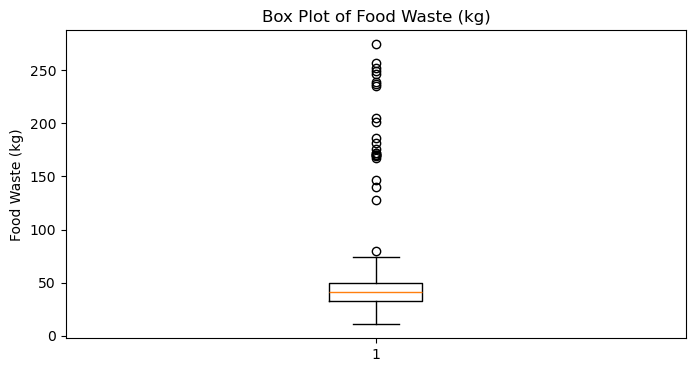

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.boxplot(df["food_waste_kg"])
plt.title("Box Plot of Food Waste (kg)")
plt.ylabel("Food Waste (kg)")
plt.show()

### Step 2: Distribution of food waste

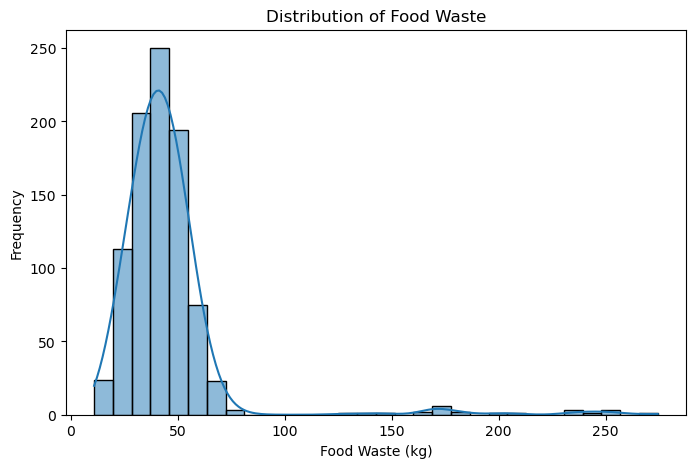

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="food_waste_kg", bins=30, kde=True)

plt.title("Distribution of Food Waste")
plt.xlabel("Food Waste (kg)")
plt.ylabel("Frequency")
plt.show()

**Observation:** The histogram shows that food waste is concentrated mainly between 30 kg and 60 kg. The distribution is positively skewed due to a few observations with very high food-waste values. These extreme values may be potential outliers and should be investigated further before any removal or transformation is performed.

### Step 3: Food waste by category

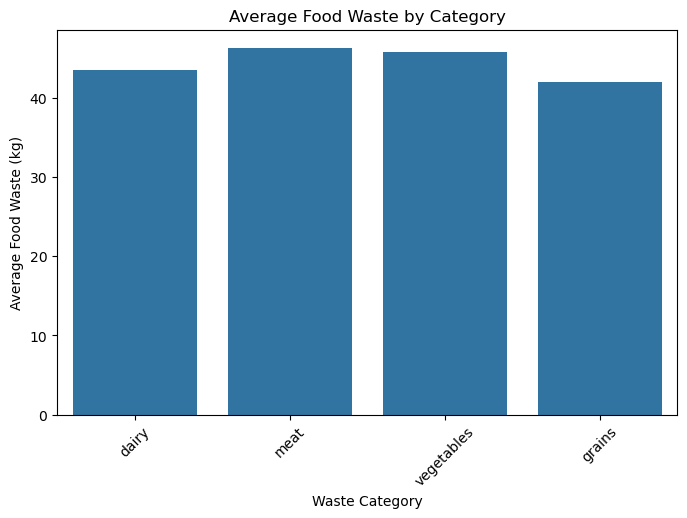

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="waste_category",
    y="food_waste_kg",
    estimator="mean",
    errorbar=None
)

plt.title("Average Food Waste by Category")
plt.xlabel("Waste Category")
plt.ylabel("Average Food Waste (kg)")
plt.xticks(rotation=45)
plt.show()

**Observation:** The bar chart shows that meat has the highest average food waste, followed closely by vegetables and dairy. Grains have the lowest average food waste. However, the differences between the categories are relatively small. Further analysis is needed to determine whether waste category is an important factor in predicting food waste.

### Step 4: Food waste versus meals served

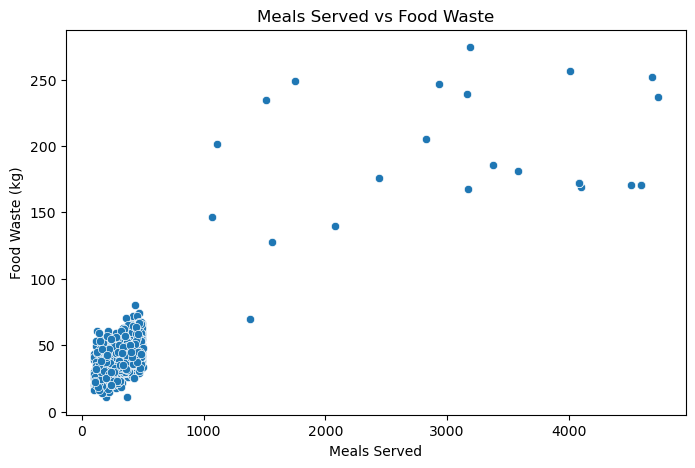

In [28]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="meals_served",
    y="food_waste_kg"
)

plt.title("Meals Served vs Food Waste")
plt.xlabel("Meals Served")
plt.ylabel("Food Waste (kg)")
plt.show()

**Observation:** The scatter plot shows that most observations are concentrated below 600 meals served and 80 kg of food waste. A few observations have much higher meal counts and food-waste values. A possible positive relationship may exist between meals served and food waste, but it is difficult to confirm from the plot alone. The extreme values should be investigated before further analysis.

### Step 5: Correlation heatmap

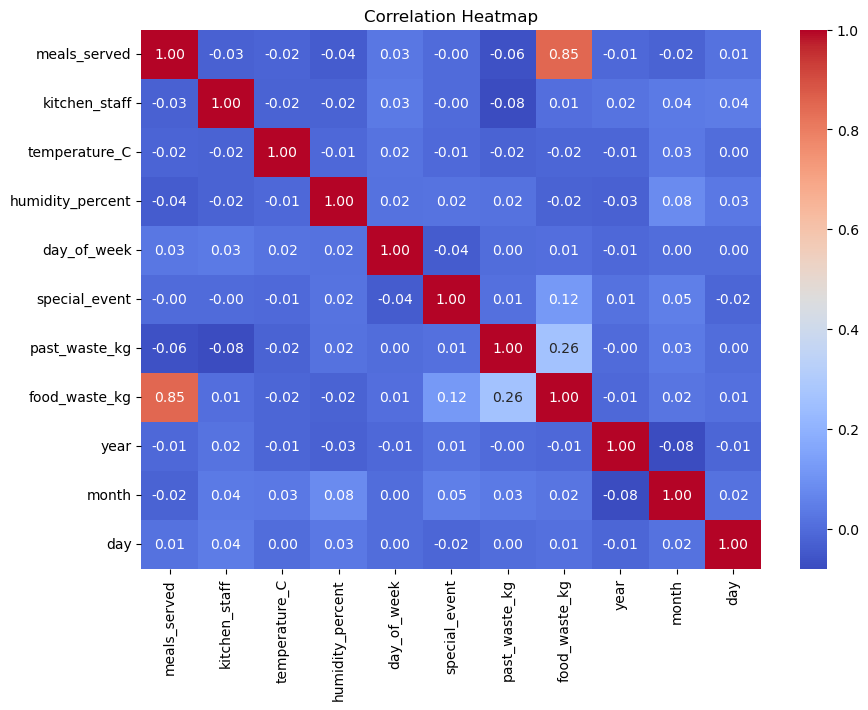

In [29]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

**Observation:** The correlation heatmap indicates a strong positive relationship between meals served and food waste, with a correlation coefficient of 0.85. Past food waste shows a weak positive correlation of 0.26, while special events have a correlation of 0.12. The remaining numerical variables show very weak linear relationships with food waste. Therefore, meals served appears to be an important feature for predicting food waste.

### Step 6: Average food waste by month

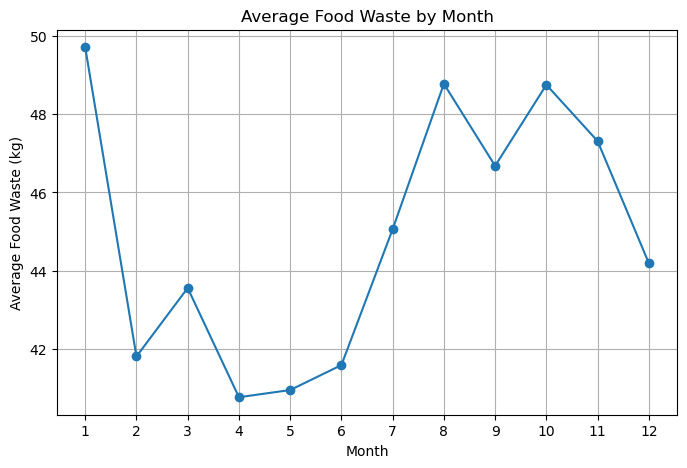

In [30]:
monthly_waste = df.groupby("month")["food_waste_kg"].mean()

monthly_waste.plot(kind="line", marker="o", figsize=(8, 5))

plt.title("Average Food Waste by Month")
plt.xlabel("Month")
plt.ylabel("Average Food Waste (kg)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

**Observation:** The line chart shows monthly variations in average food waste. January records the highest average food waste, while April records the lowest. Average food waste increases during July and August and reaches another peak in October before declining toward December. These variations may indicate seasonal patterns, but further analysis is required to identify the factors responsible for them.

# Train/test split and preprocessing

### Step 1: Separate input features and target

In [31]:
X = df.drop(columns=["food_waste_kg"])
y = df["food_waste_kg"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (911, 13)
Target shape: (911,)


### Step 2: Split the data

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 728
Testing rows: 183


### step 3.Check the column types

In [33]:
print("Categorical columns:")
print(X_train.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumerical columns:")
print(X_train.select_dtypes(include="number").columns.tolist())

print("\nDate columns:")
print(X_train.select_dtypes(include=["datetime"]).columns.tolist())

Categorical columns:
['staff_experience', 'waste_category']

Numerical columns:
['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'year', 'month', 'day']

Date columns:
['date']


# step 4:Extract features from the date

In [34]:
for dataset in [X_train, X_test]:
    dataset["date"] = pd.to_datetime(dataset["date"])

    dataset["year"] = dataset["date"].dt.year
    dataset["month"] = dataset["date"].dt.month
    dataset["day"] = dataset["date"].dt.day
    dataset["day_of_week"] = dataset["date"].dt.dayofweek

    dataset.drop(columns=["date"], inplace=True)

### Encoding

In [35]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

Categorical columns: ['staff_experience', 'waste_category']


In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

In [37]:
print("Categorical columns used by encoder:")
print(categorical_cols)

print("\nPreprocessor details:")
print(preprocessor)

Categorical columns used by encoder:
['staff_experience', 'waste_category']

Preprocessor details:
ColumnTransformer(remainder='passthrough',
                  transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['staff_experience', 'waste_category'])])


# Train the models

### 1.Linear Regression

In [38]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

C:\Users\JP\Projects\Lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['staff_experience',
                                                   'waste_category'])])),
                ('model', LinearRegression())])

# 2.Decision Tree Regressor

In [39]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


# 3.Random Forest Regressor

In [40]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


# Make predictions and Evaluation metrics

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
models = {
    "Linear Regression": linear_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="RMSE")

print(results_df.round(3))

               Model    MAE    RMSE  R2 Score
2      Random Forest  4.655   6.929     0.906
1      Decision Tree  6.309  10.985     0.764
0  Linear Regression  5.637  11.496     0.742


# Visualize the model comparison

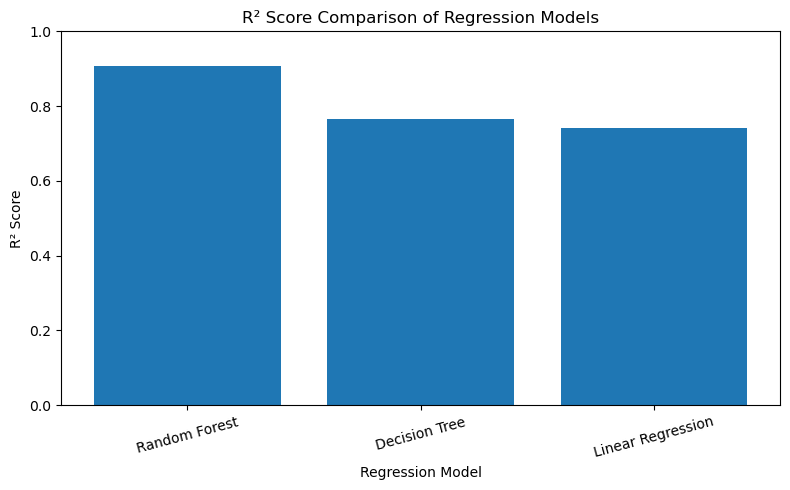

In [42]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Actual vs. Predicted Food Waste

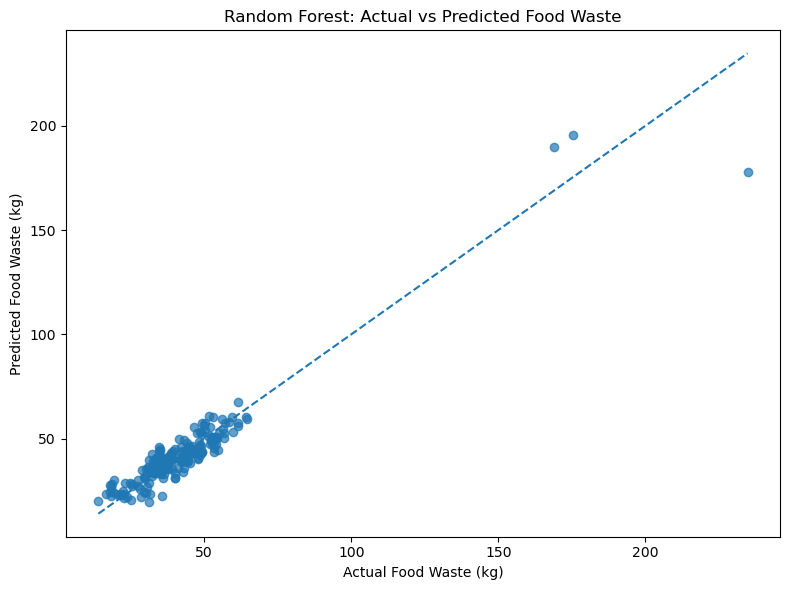

In [43]:
# Predict using the best-performing model
y_pred_rf = rf_model.predict(X_test)

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.7)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Food Waste (kg)")
plt.ylabel("Predicted Food Waste (kg)")
plt.title("Random Forest: Actual vs Predicted Food Waste")
plt.tight_layout()
plt.show()

# Residual analysis

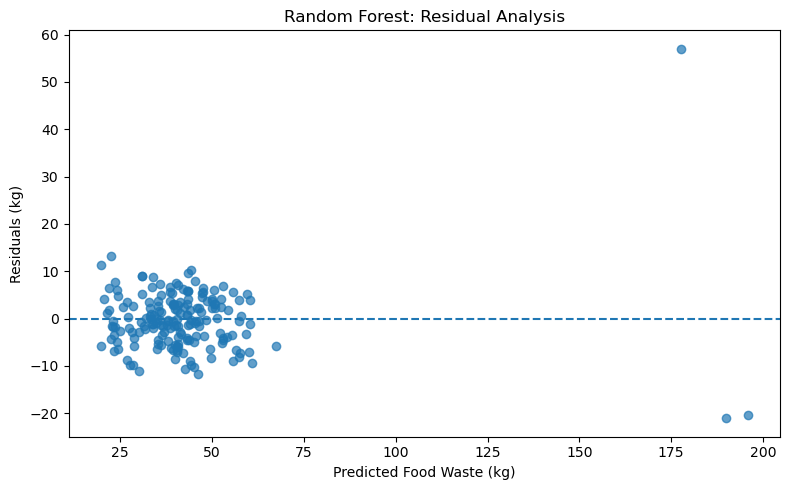

In [44]:
# Calculate residuals
residuals = y_test - y_pred_rf

# Plot residuals
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_rf, residuals, alpha=0.7)

# Zero-error reference line
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Food Waste (kg)")
plt.ylabel("Residuals (kg)")
plt.title("Random Forest: Residual Analysis")
plt.tight_layout()
plt.show()

## Conclusion

In this project, we developed machine learning models to predict food waste in kilograms using the Food Waste Dataset.

The project included data cleaning, exploratory data analysis (EDA), data visualization, feature and target selection, train-test splitting, categorical encoding, and regression model development.

Three regression algorithms were trained and evaluated: Linear Regression, Decision Tree Regressor, and Random Forest Regressor.

### Model Comparison

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score.

- **Random Forest Regressor:** MAE = 4.655, RMSE = 6.929, R² = 0.906
- **Decision Tree Regressor:** MAE = 6.309, RMSE = 10.985, R² = 0.764
- **Linear Regression:** MAE = 5.637, RMSE = 11.496, R² = 0.742

### Final Finding

Among the three models tested, the Random Forest Regressor performed best on the test dataset. It achieved the lowest MAE and RMSE and the highest R² score. Its predictions had an average absolute error of approximately 4.655 kg, and it explained approximately 90.6% of the variation in the test-set target values.

The actual-versus-predicted plot also showed that predictions were generally close to actual values, although some unusually high food-waste values were less accurately predicted.




# Predict food waste on new data

In [45]:
print(X_train.columns.tolist())

['meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'staff_experience', 'waste_category', 'year', 'month', 'day']


### Create new input data

In [46]:
new_data = pd.DataFrame([{
    "meals_served": 150,
    "kitchen_staff": 8,
    "temperature_C": 23.0,
    "humidity_percent": 60.0,
    "day_of_week": 7,
    "special_event": "1",
    "past_waste_kg": 30.0,
    "staff_experience": "Intermediate",
    "waste_category": "vegetables",
    "year": 2026,
    "month": 10,
    "day": 27
}])

new_data

,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,year,month,day
0,150,8,23.0,60.0,7,1,30.0,Intermediate,vegetables,2026,10,27


In [47]:
predicted_waste = rf_model.predict(new_data)

print(
    f"Predicted food waste: {predicted_waste[0]:.2f} kg"
)

Predicted food waste: 39.76 kg


In [48]:
import joblib

joblib.dump(rf_model, "food_waste_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [49]:
import sklearn
print(sklearn.__version__)

1.6.1
